In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve

pd.set_option("display.max_columns", None)
%matplotlib inline
DATA_DIR = Path("data/processed")
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e6e5e1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "figure.dpi": 110})


## 1. Load data

In [3]:
train = pd.read_csv(DATA_DIR / "fraudTrain_features.csv")

X_train_full = train.drop(columns=["is_fraud"]).astype("float32")
y_train_full = train["is_fraud"]
print("train:", X_train_full.shape, f"fraud rate {y_train_full.mean():.3%}")

train: (1296675, 110) fraud rate 0.579%


## 2. Train / validation split

The engineered training data remains in chronological order. The first 80% is used to fit the Random Forest, while the final 20% is held out as an out-of-time validation period.

The validation set is used to select the best tree configuration and fraud decision threshold using PR-AUC and F1-score. The test set is not loaded or evaluated in this notebook.

In [4]:
cut = int(len(X_train_full) * 0.8)

X_tr, y_tr = X_train_full.iloc[:cut], y_train_full.iloc[:cut]
X_val, y_val = X_train_full.iloc[cut:], y_train_full.iloc[cut:]

split_sizes = pd.DataFrame({
    "split": ["fit", "validation"],
    "rows": [len(X_tr), len(X_val)],
    "fraud": [y_tr.sum(), y_val.sum()],
    "fraud rate": [f"{y_tr.mean():.3%}", f"{y_val.mean():.3%}"],
}).set_index("split")
split_sizes

,rows,fraud,fraud rate
split,,,
fit,1037340,5968,0.575%
validation,259335,1538,0.593%


## 3. Random Forest pipeline

Random Forests do not require feature scaling. `class_weight="balanced_subsample"` compensates for the rare fraud class in each bootstrap sample. The threshold is tuned separately because the probability scores are used primarily for ranking.


In [5]:
def make_model(max_depth=None, min_samples_leaf=2):
    # Trees are fitted in parallel threads that share one copy of the training data; results do not depend on n_jobs.
    return RandomForestClassifier(n_estimators=100, max_depth=max_depth, min_samples_leaf=min_samples_leaf, max_features="sqrt", class_weight="balanced_subsample", n_jobs=-1, random_state=42)


def best_f1_threshold(y, proba):
    precision, recall, thresholds = precision_recall_curve(y, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[np.argmax(f1)])


def scores_at(y, proba, threshold):
    alert = proba >= threshold
    caught = int((alert & (y == 1)).sum())
    return {
        "alerts": int(alert.sum()),
        "frauds caught": caught,
        "false alarms": int(alert.sum()) - caught,
        "precision": caught / max(int(alert.sum()), 1),
        "recall": caught / int((y == 1).sum()),
    }


### 4a. Tree hyperparameter tuning

We evaluate several Random Forest configurations using the chronological validation set.

The candidates vary:

- `max_depth`: maximum depth of each tree
- `min_samples_leaf`: minimum number of observations required in a leaf

Each model is trained on the fitting data (`X_tr`, `y_tr`) and evaluated on the validation data (`X_val`, `y_val`). The configuration with the highest validation PR-AUC is selected.

Validation PR-AUC and ROC-AUC are reported for the selected configuration. The test set is not used.

In [6]:
candidates = [(12, 2), (20, 2), (None, 2)]
results, models = [], {}
for max_depth, min_leaf in candidates:
    key = (max_depth, min_leaf)
    models[key] = make_model(max_depth, min_leaf).fit(X_tr, y_tr)
    proba = models[key].predict_proba(X_val)[:, 1]
    results.append({"max_depth": max_depth, "min_samples_leaf": min_leaf, "val PR-AUC": average_precision_score(y_val, proba), "val ROC-AUC": roc_auc_score(y_val, proba)})
rf_results = pd.DataFrame(results)
best_index = rf_results["val PR-AUC"].idxmax()
best_key = candidates[best_index]
model = models[best_key]
val_proba = model.predict_proba(X_val)[:, 1]
print(f"Best settings: max_depth={best_key[0]}, min_samples_leaf={best_key[1]}")
print(f"Validation PR-AUC: {average_precision_score(y_val, val_proba):.4f} (random = {y_val.mean():.4f})")
print(f"Validation ROC-AUC: {roc_auc_score(y_val, val_proba):.4f}")
rf_results.round(4)


Best settings: max_depth=None, min_samples_leaf=2
Validation PR-AUC: 0.9448 (random = 0.0059)
Validation ROC-AUC: 0.9961


,max_depth,min_samples_leaf,val PR-AUC,val ROC-AUC
0,12.0,2,0.8693,0.9965
1,20.0,2,0.9167,0.9976
2,NaN,2,0.9448,0.9961


### 4b. Decision threshold

The threshold that maximises fraud F1 on validation data is fixed before test evaluation.



In [7]:
threshold = best_f1_threshold(y_val, val_proba)
print(f"Validation standalone threshold: {threshold:.3f}")
pd.DataFrame({f"standalone ({threshold:.3f})": scores_at(y_val, val_proba, threshold)}).T.round(3)

final_model = make_model(*best_key).fit(X_train_full, y_train_full)


Validation standalone threshold: 0.319


## 5. Validation decision threshold

The default 0.5 threshold is poorly suited here: because of the class weighting it flags far too many legitimate transactions. The threshold that maximises **F1** (the balance of precision and recall) on the validation set is chosen instead. If the business cost of a missed fraud is much higher than a false alarm, a lower threshold (higher recall) could be picked from the same curve.

## 6. Feature importance

Random Forest feature importance measures the average impurity reduction contributed by each feature. These are predictive associations, not causal effects.


In [8]:
importances = pd.DataFrame({"feature": X_train_full.columns, "importance": final_model.feature_importances_}).sort_values("importance", ascending=False).reset_index(drop=True)
importances.head(20).round(5)


,feature,importance
0,beh_log_amt_sum_24h,0.17630
1,log_amt,0.13704
2,amt,0.13100
3,amt_is_large,0.10437
4,hour_cos,0.07788
5,beh_amt_to_cust_avg,0.07063
6,kyc_amt_to_declared_spend,0.04389
7,kyc_amt_to_credit_limit,0.03636
8,hour,0.03518
9,hour_sin,0.02231


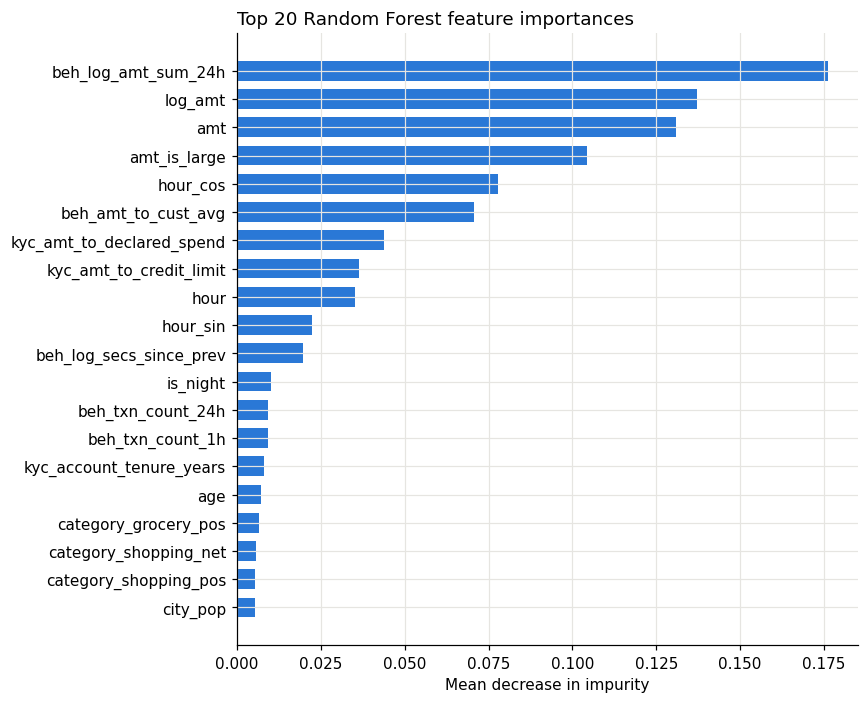

In [9]:
top = importances.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top["feature"], top["importance"], color=BLUE, height=0.7)
ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Top 20 Random Forest feature importances", loc="left")
plt.tight_layout(); plt.show()


## 7. Validation results summary

The Random Forest hyperparameters and standalone threshold are selected using validation PR-AUC and validation F1. Test labels are not loaded or evaluated in this notebook.

| Model | Validation PR-AUC |
|---|---:|
| Random Forest | 0.945 |
